# 03 · What each receptor class reads

Ligands per receptor by class, and the odorants each class reads. An odorant is read by a
class when it activates at least 1/62 of that class's receptors (one class I receptor, six
class II receptors). The class I only and class II only sets are compared on functional
groups, descriptors and odour descriptors; the shared set is reported for context.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd

REPO = Path("../..").resolve()
sys.path.append(str(REPO / "Downstream_Analysis/scripts"))
sys.path.append(str(REPO / "scripts"))
import matplotlib.pyplot as plt
import activation_code as ac
import activation_figures as af
from plotting_functions import custom_plots

plt.rcParams.update(custom_plots())

PROBABILITIES = REPO / "Downstream_Analysis/predictions/aggregated/Reference_Tree_Predictions/reference_median_probability_wide.csv"
M2OR_PAIRS = REPO / "Model_Inputs/Data_Preparation/processed/m2or_pairs_model.csv"
ODOURS = REPO / "Chemicals/processed_data/m2or_inchi_odors_smiles.csv"
FASTA = REPO / "Phylogenetic_Analysis/data/ReferenceTree/PF13853.9606_7955_7740_7764_75743_137246.fa"
CLASSES = REPO / "Phylogenetic_Analysis/data/HumanTree/human433_OR_classes.csv"
TABLES = Path("results")
TABLES.mkdir(exist_ok=True)
FIGURES = Path("figures")
FIGURES.mkdir(exist_ok=True)

In [2]:
hybrid_table = pd.read_csv(TABLES / "hybrid_matrix.csv", index_col=0)
receptor_ids = list(hybrid_table.index)
odorant_ids = list(hybrid_table.columns)
hybrid = hybrid_table.values
clusters = pd.read_csv(TABLES / "odorant_clusters.csv")
info, display_order = ac.clusters_from_table(clusters)
clustered_ids = clusters.smiles_id.values
labels = clusters.cluster.values
smiles_by_odorant, tags_by_odorant = ac.odour_tags(M2OR_PAIRS, ODOURS, odorant_ids)
class_of = ac.receptor_classes(CLASSES)

In [3]:
breadth = ac.tuning_breadth(hybrid, receptor_ids, class_of)
breadth["table"].to_csv(TABLES / "class_breadth.csv", index=False)
breadth_test = ac.breadth_test(breadth)
breadth_test.to_csv(TABLES / "class_breadth_test.csv", index=False)

for label, values in [("Class I", breadth["class_I"]), ("Class II", breadth["class_II"])]:
    print(f"{label:9s} n={len(values):3d}  median {np.median(values):g}  orphans {(values == 0).sum()}")
breadth_test

Class I   n= 62  median 8.5  orphans 9
Class II  n=371  median 4  orphans 49


,comparison,mann_whitney_p,cliffs_delta,shift_ligands,shift_low,shift_high
0,all receptors,0.018526,0.186158,2.0,0.0,8.0
1,orphans excluded,0.001667,0.268546,5.0,1.0,14.0


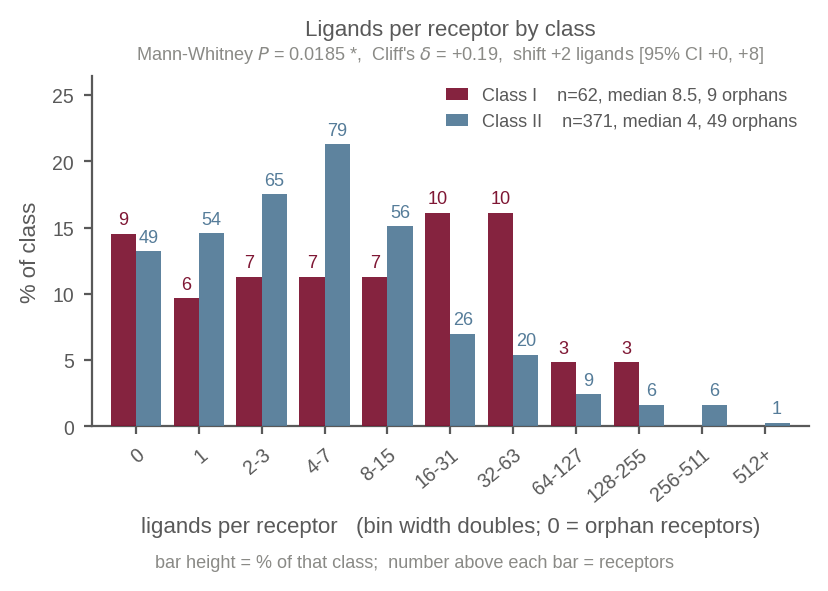

In [4]:
# Ligands per receptor by class (Fig. 2b).
af.breadth_histogram(pd.read_csv(TABLES / "class_breadth.csv"), pd.read_csv(TABLES / "class_breadth_test.csv"),
                     FIGURES / "class_breadth.svg")

In [5]:
groups, rate, rate_I, rate_II, in_I, in_II = ac.class_partition(hybrid, receptor_ids, class_of)
for g in ac.CLASS_SETS:
    print(f"{g:14s} {(groups == g).sum()}")

class_odorants = ac.class_set_descriptors(odorant_ids, smiles_by_odorant, groups, rate_I, rate_II, in_I, in_II)
class_odorants.to_csv(TABLES / "class_set_odorants.csv", index=False)

class_groups = ac.class_group_tests(class_odorants)
class_groups.to_csv(TABLES / "class_functional_groups.csv", index=False)
class_effects = ac.class_descriptor_effects(class_odorants)
class_effects.to_csv(TABLES / "class_descriptor_effects.csv", index=False)
class_groups.round(4)

Class I only   111
shared         276
Class II only  112


,group,Class I only,shared,Class II only,p,q
0,carboxylic acid,47.7477,4.3478,0.0000,0.0000,0.0000
1,ester,15.3153,31.1594,12.5000,0.5673,0.6382
2,aldehyde,6.3063,13.0435,12.5000,0.1678,0.2158
3,ketone,12.6126,15.9420,25.8929,0.0169,0.0304
4,alcohol,15.3153,17.3913,16.9643,0.8559,0.8559
5,ether,8.1081,16.3043,17.8571,0.0451,0.0677
6,aromatic ring,16.2162,44.2029,32.1429,0.0076,0.0296
7,amine,5.4054,4.7101,0.0000,0.0142,0.0304
8,sulfur,8.1081,6.5217,0.8929,0.0099,0.0296


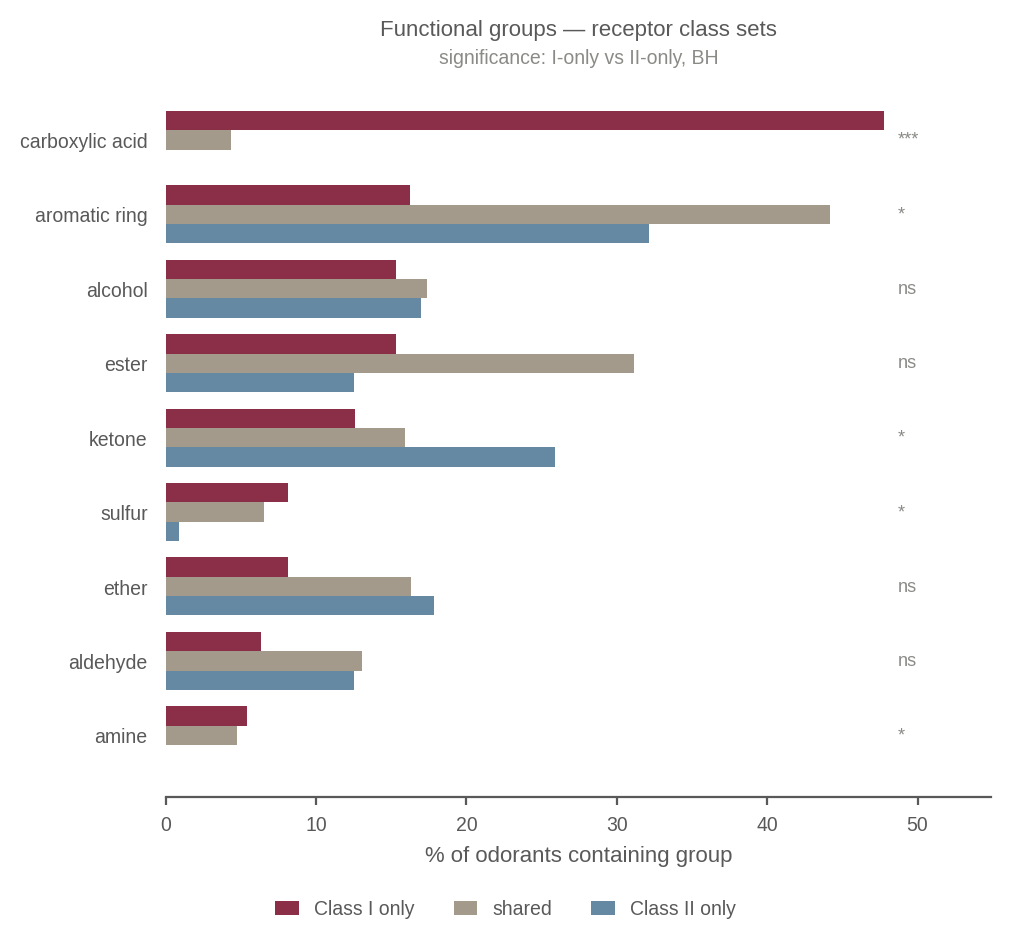

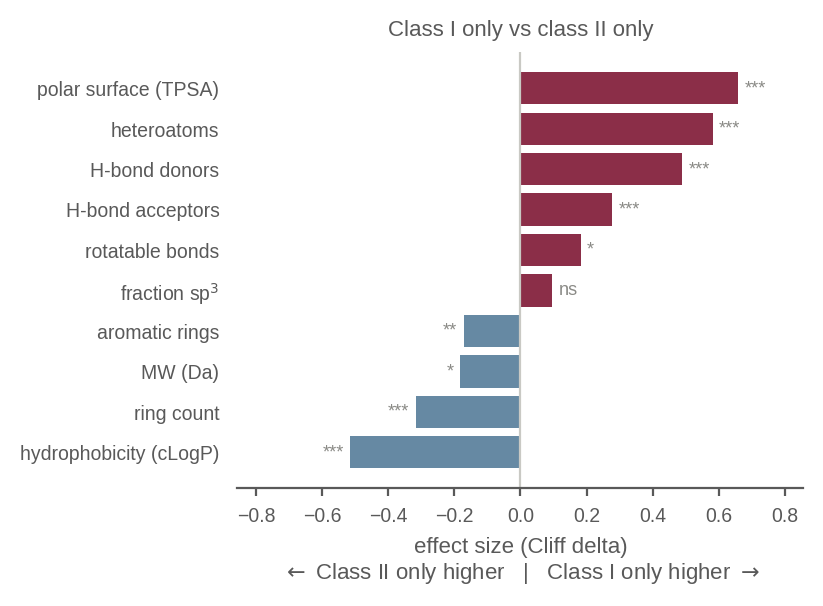

In [6]:
# Functional groups and descriptors of the odorants each class reads (Fig. 2c).
af.class_functional_groups(pd.read_csv(TABLES / "class_functional_groups.csv"), "receptor class sets",
                           FIGURES / "class_functional_groups.svg", show=True)
af.cliffs_figure(pd.read_csv(TABLES / "class_descriptor_effects.csv"), "Class I only vs class II only",
                 FIGURES / "class_descriptor_effects.svg", show=True)

In [7]:
tag_tables = []
for comparison, members_I, members_II, test in [("full sets", in_I, in_II, False),
                                                ("exclusive", in_I & ~in_II, in_II & ~in_I, True)]:
    table, _, n_tagged_I, n_tagged_II = ac.tag_percentages(members_I, members_II, odorant_ids, tags_by_odorant,
                                                           test=test)
    table.insert(0, "comparison", comparison)
    table["n_tagged_I"], table["n_tagged_II"] = n_tagged_I, n_tagged_II
    tag_tables.append(table)
class_tags = pd.concat(tag_tables, ignore_index=True)
class_tags.to_csv(TABLES / "class_odour_tags.csv", index=False)

class_tags[(class_tags.comparison == "exclusive") & (class_tags.q < 0.05)][["tag", "n_I", "n_II", "pct_I", "pct_II", "q"]]

,tag,n_I,n_II,pct_I,pct_II,q
144,sour,14,0,20.000000,0.000000,0.000882
145,cheesy,13,3,18.571429,3.947368,0.046031
146,buttery,11,1,15.714286,1.315789,0.023025
147,pineapple,11,1,15.714286,1.315789,0.023025
148,acidic,8,0,11.428571,0.000000,0.024651
268,musk,1,11,1.428571,14.473684,0.038749
271,fresh,3,16,4.285714,21.052632,0.025529
272,powdery,2,15,2.857143,19.736842,0.023025


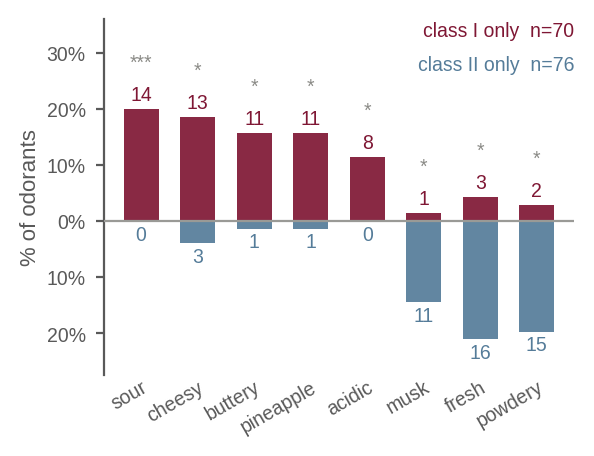

In [8]:
# Odour descriptors that differ between the exclusive class sets (Fig. 2d).
tags = pd.read_csv(TABLES / "class_odour_tags.csv")
af.class_tag_bars(tags[tags.comparison == "exclusive"], FIGURES / "class_odour_tags.svg", show=True)